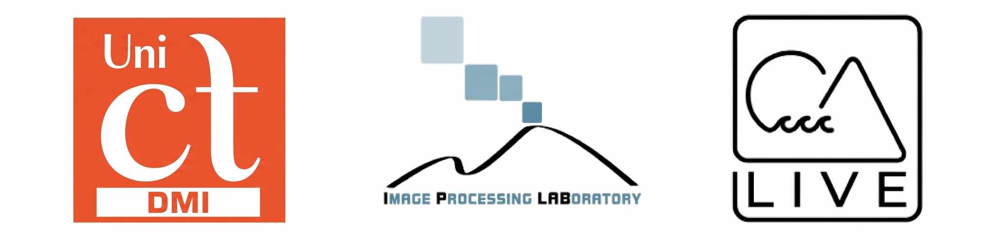

<br><br>

<h2 align="center">Deep Learning - Core Models and Methods - A.A. 2026-2027</h2>
<h3 align="center">Convolutional Neural Networks</h3>

<br>

<p align="center">
    Francesco Ragusa - <a href="https://francescoragusa.github.io/" target="_blank">https://francescoragusa.github.io/</a> - <a href="mailto:francesco.ragusa@unict.it">francesco.ragusa@unict.it</a>
    <br>
    Giovanni Maria Farinella - <a href="http://www.dmi.unict.it/farinella/" target="_blank">http://www.dmi.unict.it/farinella/</a> - <a href="mailto:giovanni.farinella@unict.it">giovanni.farinella@unict.it</a>
</p>

Le Convolutional Neural Networks (CNN) permettono di applicare le reti neurali in maniera efficiente al processamento di immagini e video. Abbiamo già visto come sia possibile classificare immagini mediante un regressore softmax o un multilayer perceptron. Tuttavia, vista l'alta dimensionalità delle immagini, tali metodi tendono a non scalare a immagini di grandi dimensioni e a grossi dataset di immagini. Le Convolutional Neural Networks cercano di risolvere questi problemi sostituendo le transformazioni lineari con le convoluzioni, che richiedono meno parametri e presentano invarianza traslazionale.

**NOTA**: In questo laboratorio, i modelli vengono allenati per 50/150 epoche. Questi parametri richiedono lunghi tempi di allenamento anche se si utilizza la GPU. Ai fini del completamento del laboratorio in aula, si consiglia di allenare i modelli solo per qualche epoca (a fini didattici) e di ripetere tutti gli addestramenti una volta a casa (il processo richiederà delle ore).

## 1 LeNet
Iniziamo implementando un modello molto simile a LeNet-5, il primo esempio di CNN presente in letteratura (LeCunn et al. 1998). Il modello è stato proposto nel 1998 per risolvere il problema della classificazione di cifre del dataset MNIST-DIGITS. Il modello qui presentato differisce da quello originale in diversi dettagli, ma la sua struttura resta fedele all'originale. La seguente figura mostra uno schema del modello LeNet considerato:

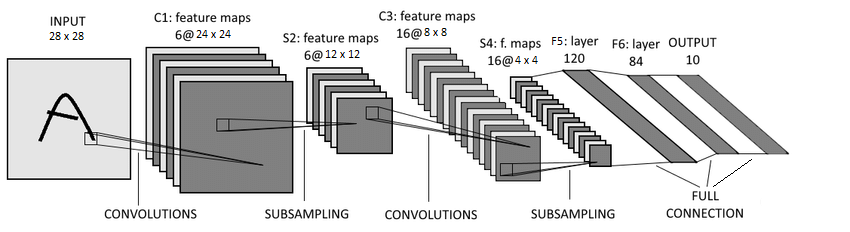


Il modello prevede sette layers:

 * Un layer di convoluzione C1. Il layer prende in input una immagine di dimensione $28 \times 28$ pixels e un unico canale. Mediante l'applicazione di $6$ kernel di convoluzione di dimensioni $5 \times 5$, vengono calcolate $6$ mappe di features. Nessun tipo di padding viene applicato, dunque ogni mappa di features ha dimensioni $24 \times 24$. In pratica, l'input del layer C1 è un tensore di dimensione $1 \times 28 \times 28$, mentre il suo output è un tensore di dimensione $6 \times 24 \times 24$. Ogni convoluzione viene effettuata applicando un kernel di dimensione $5 \times 5$ e sommando al risultato un termine di bias. Il numero totale di parametri ottimizzabili del livello C1 è dunque pari a $6 \times (5 \times 5 +1) = 156$;
 * Un layer di sottocampionamento S2. Il layer prende in input le 6 mappe $24 \times 24$ e le sottocampiona ottenendo in output mappe di dimensioni $12 \times 12$. Il sottocampionamento è effettuato suddividendo la mappa in input in intorni $2 \times 2$ e calcolando il valore medio di ognuno di questi intorni (average pooling); In pratica, l'input del layer è un tensore di dimensione $6 \times 24 \times 24$, mentre il suo output è un tensore di dimensione $6 \times 12 \times 12$. Il layer non contiene alcun parametro ottimizzabile;
 * Un layer di convoluzione C3. Il layer prende in input il tensore di dimensioni $6 \times 12 \times 12$ e calcola $16$ mappe di feature di dimensioni $8 \times 8$ utilizzando kernel di dimensioni $5 \times 5$. Il numero di parametri ottimizzabili è pari a  $16 \times (6 \times 5 \times 5 + 1)= 2416$;
 * Un layer di sottocampionamento S4. In maniera del tutto simile al layer S2, prende in input $16$ mappe di dimensione $8 \times 8$ e produce $16$ mappe di dimensione $4 \times 4$. Anche questo livello non contiene parametri ottimizzabili;
 * Un layer di trasformazione lineare "fully connected" F5. Il layer prende in input il tensore di dimensioni $16 \times 4 \times 4$. Il tensore viene dunque considerato come un vettore monodimensionale di $256$ unità e trasformato (mediante trasformazione lineare) in un tensore di $120$ unità. Il numero totale di parametri è dato da $120 \times 256 + 120 = 30840$ (l'ultimo "+120" rappresenta i parametri di bias);
 * Un layer di trasformazione lineare F6. Il layer prende in input il vettore di $120$ unità e lo trasforma in un vettore di $84$ unità. Il numero di parametri ottimizzabili è pari a $84 \times 120 + 84 = 10164$;
 * Un layer di trasformazione lineare F7. Il layer prende in input il vettore di $84$ unità e lo trasforma in un vettore di $10$ unità (gli score relativi alle $10$ classi di MNIST-DIGITS). Il numero di parametri ottimizzabili del livello è pari a $84 \times 10+10 = 850$.

Il numero totale di parametri del modello è pari a $44426$. Tra ogni coppia di layer, tranne che subito dopo i layer di sottocampionamento, è presente una attivazione di tipo TanH.



 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 1**

Perchè i layer di convoluzione (C1, C3) riducono le dimensioni delle mappe in input? Secondo quale formula le dimensioni vengono ridotte?

**Risposta**: I layer di convoluzione C1 e C3 riducono le dimensioni delle mappe perché la convoluzione si calcola senza padding (padding=0, il default di nn.Conv2d) e con stride 1. Il kernel $5 \times 5$ si può quindi posizionare solo dove cade interamente dentro la mappa: il suo centro non può trovarsi sulle prime 2 né sulle ultime 2 righe e colonne. Per ogni dimensione si perdono quindi $K-1 = 4$ pixel. La formula è:

$$
W_{out} = \left\lfloor \frac{W_{in} - K + 2P}{S} \right\rfloor + 1
$$

 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 2**

Si confronti il numero di parametri di LeNet con quelli di un multilayer perceptron con $64$ unità nascoste. Quale dei due modelli contiene meno parametri? A cosa è dovuta la differenza?

**Risposta**: L'MLP ha $28 * 28 * 64 + 64 + 640 + 10 = 50.890$ parametri (oltre ai parametri dell'input, ci sono i 64 bias, i 640 + 10 parametri dell'ultimo layer) parametri dell'ultimo layer e i 10 bias (uno per cl. La CNN contiene meno parametri e la differenza è dovuta al fatto che non bisogna srotolare l'input e creare una rete feed-forward.

Prima di iniziare a scrivere del codice, impostiamo un seed:

In [1]:
import torch
import numpy as np
np.random.seed(1328)
torch.random.manual_seed(1328);

Implementiamo adesso il modello LeNet:

In [2]:
from torch import nn
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        #Definiamo il primo livello. Dobbiamo effettuare una convoluzione 2D (ovvero su immagini)
        #Utilizziamo il modulo Conv2d che prende in input:
        #  - il numero di canali in input: 1 (si tratta di immagini in scala di grigio)
        #  - il numero di canali in output: 6 (le mappe di feature)
        #  - la dimensione del kernel: 5 (sta per "5 X 5")
        self.C1 = nn.Conv2d(1, 6, 5)
        #Definiamo il livello di subsampling. Questo viene implementato usando il modulo "AvgPool2d"
        #Il modulo richiede in input la dimensione dei neighborhood rispetto ai quali calcolare
        # i valori medi: 2
        self.S2 = nn.AvgPool2d(2)
        #Definiamo il livello C3 in maniera analoga a quanto fatto per il livello C1:
        self.C3 = nn.Conv2d(6, 16, 5)
        #Definiamo il successivo max pooling 2d
        self.S4 = nn.AvgPool2d(2)
        #Definiamo il primo layer FC
        self.F5 = nn.Linear(256, 120)
        #Definiamo il secondo layer FC
        self.F6 = nn.Linear(120, 84)
        #Definiamo il terzo layer FC
        self.F7 = nn.Linear(84, 10)

        #Definiamo inoltre un modulo per calcolare l'attivazione Tanh
        self.activation = nn.Tanh()

    def forward(self,x):
        #Applichiamo le diverse trasformazioni in cascata
        x = self.C1(x)
        x = self.S2(x)
        x = self.activation(x) #inseriamo le attivazioni ove opportuno
        x = self.C3(x)
        x = self.S4(x)
        x = self.activation(x) #inseriamo le attivazioni ove opportuno
        x = self.F5(x.view(x.shape[0],-1)) #dobbiamo effettuare un "reshape" del tensore
        x = self.activation(x)
        x = self.F6(x)
        x = self.activation(x)
        x = self.F7(x)
        return x

Definiamo il modello e verifichiamone il numero di parametri:

In [3]:
net = LeNet()
sum([p.numel() for p in net.parameters()])

44426

Carichiamo il dataset MNIST-DIGITS e definiamo i loaders

In [4]:
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
from torchvision import transforms

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = MNIST(root='mnist',train=True, download=True, transform=transform)
mnist_test = MNIST(root='mnist',train=False, download=True, transform=transform)
mnist_train_loader = DataLoader(mnist_train, batch_size=1024, num_workers=2, shuffle=True)
mnist_test_loader = DataLoader(mnist_test, batch_size=1024, num_workers=2)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 505kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.65MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.13MB/s]


Definiamo l'oggetto `AverageValueMeter` come visto nello scorso laboratorio:

In [5]:
class AverageValueMeter():
    def __init__(self):
        self.reset()

    def reset(self):
        self.sum = 0
        self.num = 0

    def add(self, value, num):
        self.sum += value*num
        self.num += num

    def value(self):
        try:
            return self.sum/self.num
        except:
            return None

Definiamo la procedura di training vista nel laboratorio precedente:

In [6]:
from torch.optim import SGD
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import accuracy_score
from os.path import join

def train_classifier(model, train_loader, test_loader, exp_name='experiment',
                     lr=0.01, epochs=10, momentum=0.99, logdir='logs'):
    criterion = nn.CrossEntropyLoss()
    optimizer = SGD(model.parameters(), lr, momentum=momentum)
    #meters
    loss_meter = AverageValueMeter()
    acc_meter = AverageValueMeter()
    #writer
    writer = SummaryWriter(join(logdir, exp_name))
    #device
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    #definiamo un dizionario contenente i loader di training e test
    loader = {
        'train' : train_loader,
        'test' : test_loader
    }
    #inizializziamo il global step
    global_step = 0
    for e in range(epochs):
        #iteriamo tra due modalità: train e test
        for mode in ['train','test']:
            loss_meter.reset(); acc_meter.reset()
            model.train() if mode == 'train' else model.eval()
            with torch.set_grad_enabled(mode=='train'): #abilitiamo i gradienti solo in training
                for i, batch in enumerate(loader[mode]):
                    x=batch[0].to(device) #"portiamoli sul device corretto"
                    y=batch[1].to(device)
                    output = model(x)

                    #aggiorniamo il global_step
                    #conterrà il numero di campioni visti durante il training
                    n = x.shape[0] #numero di elementi nel batch
                    global_step += n
                    l = criterion(output,y)

                    if mode=='train':
                        l.backward()
                        optimizer.step()
                        optimizer.zero_grad()

                    acc = accuracy_score(y.to('cpu'),output.to('cpu').max(1)[1])
                    loss_meter.add(l.item(),n)
                    acc_meter.add(acc,n)

                    #loggiamo i risultati iterazione per iterazione solo durante il training
                    if mode=='train':
                        writer.add_scalar('loss/train', loss_meter.value(), global_step=global_step)
                        writer.add_scalar('accuracy/train', acc_meter.value(), global_step=global_step)
            #una volta finita l'epoca (sia nel caso di training che test, loggiamo le stime finali)
            writer.add_scalar('loss/' + mode, loss_meter.value(), global_step=global_step)
            writer.add_scalar('accuracy/' + mode, acc_meter.value(), global_step=global_step)

        #conserviamo i pesi del modello alla fine di un ciclo di training e test
        torch.save(model.state_dict(),'%s-%d.pth'%(exp_name,e+1))
    return model

Costruiamo e alleniamo la rete LeNet:

In [7]:
lenet_mnist = LeNet()
#Ai fini didattici alleniamo il modello solo per 10 epoche invece di 50
lenet_mnist = train_classifier(lenet_mnist, mnist_train_loader,
                               mnist_test_loader, 'lenet_mnist', epochs = 10)

In [10]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

Le curve di training/test dovrebbero essere simili alle seguenti:

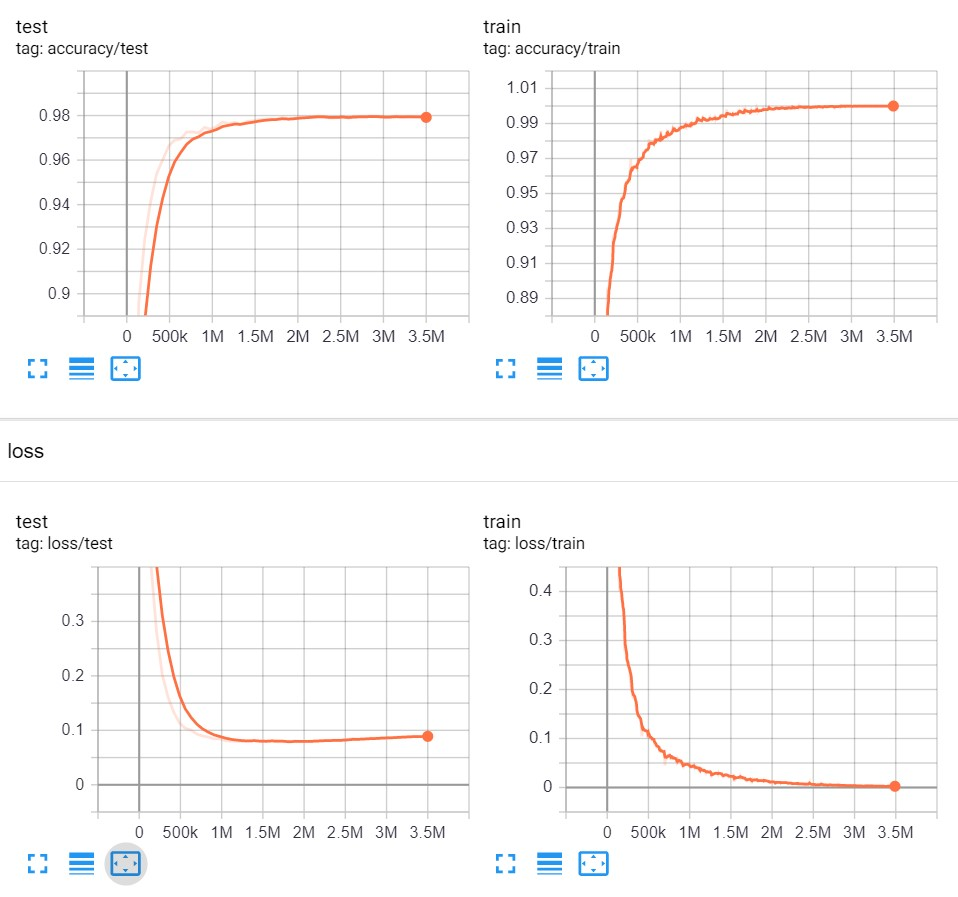

 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 3**

Si osservi il log della procedura di training. Possiamo dire che la rete converge?

**Risposta**: Sì, la rete converge. I grafici sia di training che di test mostrano che lo slope dell'errore va a diminuire verso quello che sembra un comportamento asisntotico. Un'altra conferma è che l'errore in test è molto basso (0.0915).

Definiamo la consueta funzione per ottenere probabilità di test predette dal modello:

In [11]:
def test_classifier(model, loader):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    predictions, labels = [], []
    for batch in loader:
        x = batch[0].to(device)
        y = batch[1].to(device)
        output = model(x)
        preds = output.to('cpu').max(1)[1].numpy()
        labs = y.to('cpu').numpy()
        predictions.extend(list(preds))
        labels.extend(list(labs))
    return np.array(predictions), np.array(labels)

Calcoliamo le accuracy di training e test:

In [12]:
lenet_mnist_predictions_train, mnist_labels_train = test_classifier(lenet_mnist, mnist_train_loader)
lenet_mnist_predictions_test, mnist_labels_test = test_classifier(lenet_mnist, mnist_test_loader)
print("Accuarcy di training: %0.4f"% accuracy_score(mnist_labels_train, lenet_mnist_predictions_train))
print("Accuarcy di test: %0.4f"% accuracy_score(mnist_labels_test, lenet_mnist_predictions_test))

Accuarcy di training: 0.9801
Accuarcy di test: 0.9719


Generalmente, quando le accuracy sono così alte, le performance degli algoritmi di classificazione vengono espresse sotto forma di errore percentuale di classificazione, che può essere calcolato come segue:

In [13]:
def perc_error(gt, pred):
    return (1-accuracy_score(gt,pred))*100

Calcoliamo l'errore percentuale di LeNet:

In [14]:
print ("Errore LeNet su DIGITS: %0.2f%%" % \
    perc_error(mnist_labels_test, lenet_mnist_predictions_test))

Errore LeNet su DIGITS: 2.81%


 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 4**

Si confrontino le accuracy di training e test. Possiamo dire che il modello generalizza? Perché?

**Risposta**: l'accuracy in test è praticamente uguale a quella in training. Per questo motivo si può dire che abbia generalizzato su quel dataset.

Il modello di LeNet che abbiamo definito è una versione "classica" di una CNN. I progressi nel campo della ricerca hanno sottolineato che:
 * Il max pooling funziona meglio dell'average pooling;
 * Le ReLU sono più robuste delle attivazioni di tipo Tanh.

Costruiamo una versione "più moderna" di LeNet modificando questi due elementi:

In [16]:
class LeNetV2(nn.Module):
    def __init__(self):
        super(LeNetV2, self).__init__()
        self.C1 = nn.Conv2d(1, 6, 5)
        self.S2 = nn.MaxPool2d(2)
        self.C3 = nn.Conv2d(6, 16, 5)
        self.S4 = nn.MaxPool2d(2)
        self.F5 = nn.Linear(256, 120)
        self.F6 = nn.Linear(120, 84)
        self.F7 = nn.Linear(84, 10)
        self.activation = nn.ReLU()

    def forward(self,x):
        x = self.C1(x)
        x = self.S2(x)
        x = self.activation(x)
        x = self.C3(x)
        x = self.S4(x)
        x = self.activation(x)
        x = self.F5(x.view(x.shape[0],-1))
        x = self.activation(x)
        x = self.F6(x)
        x = self.activation(x)
        x = self.F7(x)
        return x

In [17]:
# --- SANITY CHECK VISIVO: LeNetV2 ---
import torch
try:
    modello_lenet = LeNetV2()
    out_lenet = modello_lenet(torch.randn(4, 1, 28, 28))
    print(f"Shape ottenuta: {out_lenet.shape} - Attesa: torch.Size([4, 10])")
except NotImplementedError:
    print("Implementa la classe LeNetV2!")

Shape ottenuta: torch.Size([4, 10]) - Attesa: torch.Size([4, 10])


 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 5**

Si confronti il codice di LeNet con quello di LeNetV2. Quali righe di codice sono cambiate?

**Risposta**: le righe cambiate sono indicate nella cella sottostante. Abbiamo usato un MaxPooling al posto dell'average pooling e cambiato le ReLU.

In [ ]:
# self.S2 = nn.AvgPool2d(2)   →   self.S2 = nn.MaxPool2d(2)
# self.S4 = nn.AvgPool2d(2)   →   self.S4 = nn.MaxPool2d(2)
# self.activation = nn.Tanh() →   self.activation = nn.ReLU()

Alleniamo il nuovo modello:

In [18]:
lenet_v2_mnist = LeNetV2()
#Ai fini didattici alleniamo solo per 10 epoche invece di 50
lenet_v2_mnist = train_classifier(lenet_v2_mnist, mnist_train_loader,
                                  mnist_test_loader, 'lenet_v2_mnist', epochs=10)

In [19]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 3547), started 0:11:54 ago. (Use '!kill 3547' to kill it.)

<IPython.core.display.Javascript object>

Le curve di training/test dovrebbero essere simili alle seguenti:

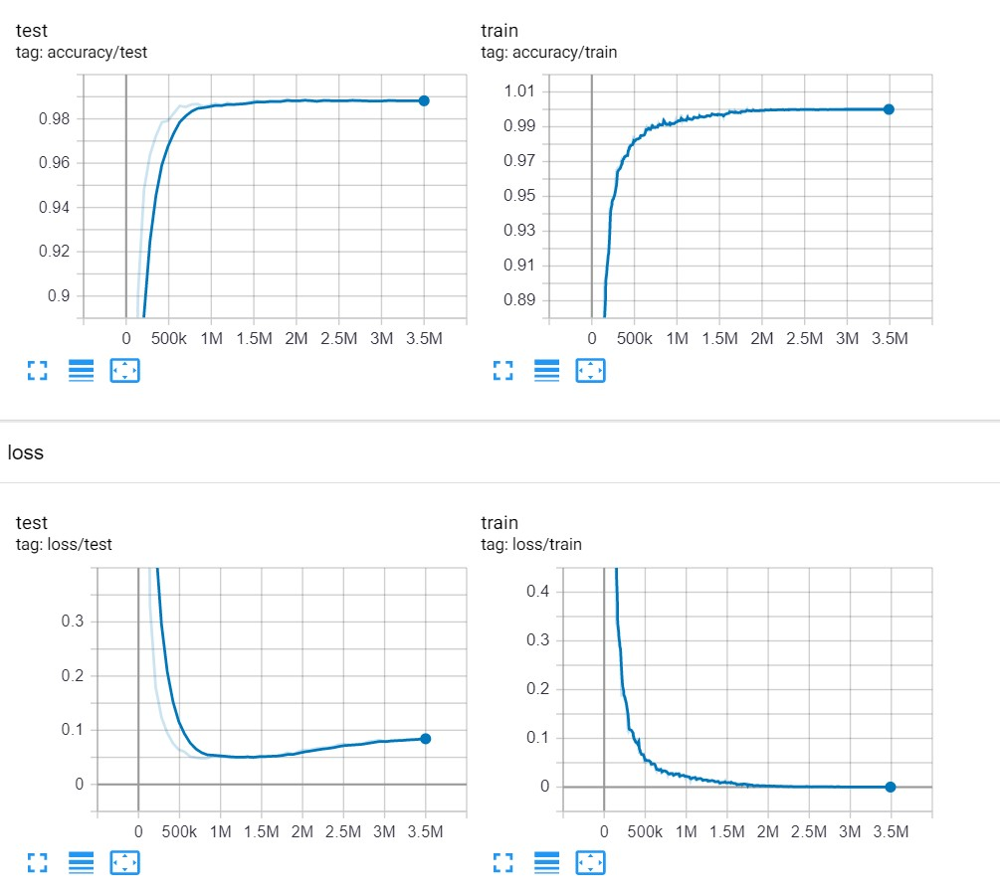

 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 6**

Si confrontino le curve di training e test di LeNetV2 con quelle di LeNetV1. Quale dei due modelli converge prima?

**Risposta**: Si vede chiaramente dai grafici che esiste un punto di incontro per il quale la rete con maxpooling e ReLU converge in tempo minore.

Calcoliamo l'errore di test e confrontiamolo con quello ottenuto in precedenza:

In [20]:
lenet_v2_mnist_predictions_test, mnist_labels_test = test_classifier(lenet_v2_mnist, mnist_test_loader)
print ("Errore LeNet su DIGITS: %0.2f%%" % \
    perc_error(mnist_labels_test, lenet_mnist_predictions_test))
print ("Errore LeNet v2 su DIGITS: %0.2f%%" % \
    perc_error(mnist_labels_test, lenet_v2_mnist_predictions_test))

Errore LeNet su DIGITS: 2.81%
Errore LeNet v2 su DIGITS: 1.72%


 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 7**

Si confrontino gli errori ottenuti con i due modelli LeNetV1 e LeNetV2. Cosa ne possiamo dedurre?

**Risposta**: riusciamo a dedurre che la rete LeNet v2 funziona meglio, perché ha un errore più basso di un punto percentuale.

## 2 Immagini Naturali e "MiniAlexNet"

Consideriamo adesso due dataset più complessi: CIFAR-100 e CIFAR-10. Ciascuno dei due dataset consiste in $60000$ immagini a colori di dimensioni $32 \times 32$. $50000$ immagini sono utilizzate per training, mentre le restanti $10000$ immagini sono utilizzate per test. Le immagini di CIFAR-100 sono suddivise in $100$ classi, mentre le immagini di CIFAR-10 sono suddivise in 10 classi. L'immagine che segue mostra alcuni esempi delle $10$ classi di CIFAR-10:

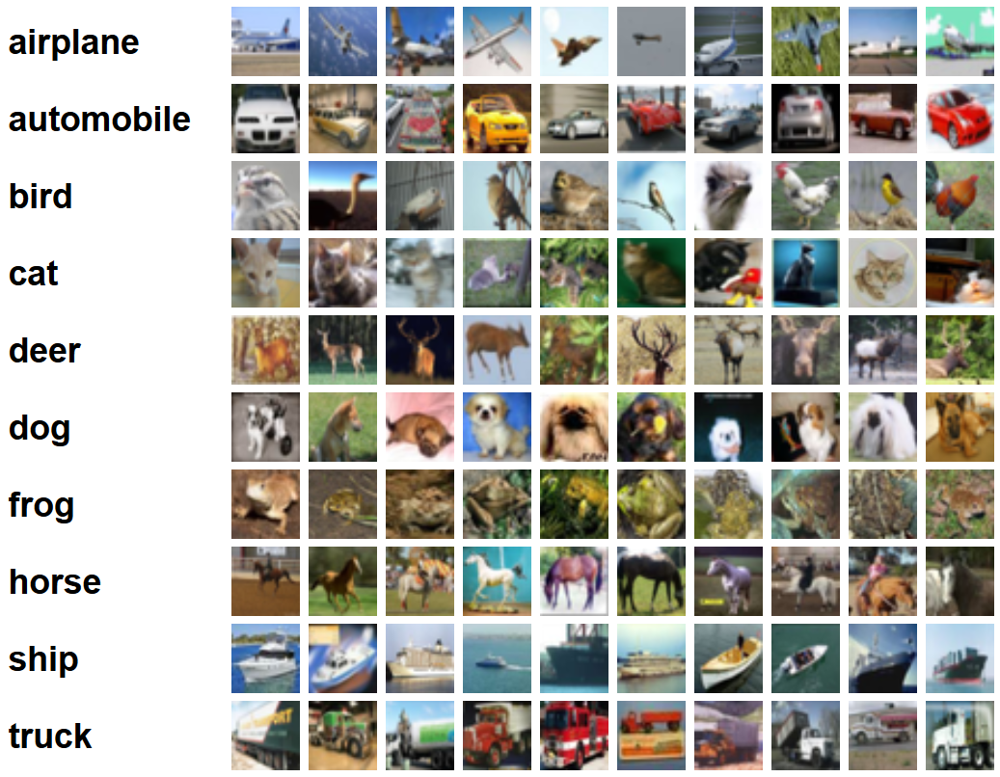

Carichiamo il dataset CIFAR-100. Normalizzeremo le immagini utilizzando le medie e varianze per canale, che sono state pre-computate (si vedano gli scorsi laboratori per un esempio su come calcolare questi valori).

In [21]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader
from torchvision import transforms

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))])
cifar100_train = CIFAR100(root='cifar100',train=True, download=True, transform=transform)
cifar100_test = CIFAR100(root='cifar100',train=False, download=True, transform=transform)
cifar100_train_loader = DataLoader(cifar100_train, batch_size=1024, num_workers=2, shuffle=True)
cifar100_test_loader = DataLoader(cifar100_test, batch_size=1024, num_workers=2)

100%|██████████| 169M/169M [23:35<00:00, 119kB/s]


Adattiamo il modello LeNetV2 per prendere in input immagini a 3 canali (RGB) di dimensione $32 \times 32$ (invece di $28 \times 28$). Aumenteremo il numero di feature maps e unità nei layer fully connected per aumentare la capacità della rete. Sostituiremo inoltre l'average Pooling con il MaxPooling e le attivazioni Tanh con le ReLU.

In [22]:
from torch import nn

class LeNetColor(nn.Module):
    def __init__(self):
        super(LeNetColor, self).__init__()

        self.feature_extractor = nn.Sequential(
            # Conv1:
            # - Input canali: 3 (immagini RGB)
            # - Output canali (feature maps): 18
            # - Dimensione Kernel: 5x5
            # - Nessun padding (padding=0)
            # (Aggiungi subito dopo Max Pooling 2x2 e ReLU)
            nn.Conv2d(3, 18, 5),
            nn.MaxPool2d(2),
            nn.ReLU(),

            # Conv2:
            # - Input canali: 18
            # - Output canali: 28
            # - Dimensione Kernel: 5x5
            # - Nessun padding (padding=0)
            # (Aggiungi subito dopo Max Pooling 2x2 e ReLU)
            nn.Conv2d(18, 28, 5),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            # FC1 (Primo layer Lineare):
            # - Calcola la dimensione esatta dell'input tenendo conto
            #   dei canali in uscita dal feature extractor (28) e
            #   della dimensione spaziale finale della feature map (da 32x32 si riduce a 5x5).
            # - Output unità: 360
            # (Aggiungi subito dopo ReLU)
            nn.Linear(28 * 5 * 5, 360),
            nn.ReLU(),

            # FC2:
            # - Input unità: 360
            # - Output unità: 252
            # (Aggiungi subito dopo ReLU)
            nn.Linear(360, 252),
            nn.ReLU(),

            # FC3 (Output finale):
            # - Input unità: 252
            # - Output unità: 100 (numero di classi di CIFAR-100)
            nn.Linear(252, 100)
        )

    def forward(self, x):
        # Applica il feature extractor, effettua il reshape del tensore
        # (flatten) per renderlo monodimensionale e passa il risultato al classificatore
        x = self.feature_extractor(x)
        x = self.classifier(x.view(x.shape[0], -1))
        return x

In [23]:
# --- SANITY CHECK VISIVO: LeNetColor ---
import torch
try:
    modello_color = LeNetColor()
    out_color = modello_color(torch.randn(4, 3, 32, 32))
    print(f"Shape ottenuta: {out_color.shape} - Attesa: torch.Size([4, 100])")
except NotImplementedError:
    print("Implementa la classe LeNetColor!")
except Exception as e:
    print(f"Errore durante l'esecuzione del modello (hai ricalcolato l'input del primo strato Linear?): {e}")

Shape ottenuta: torch.Size([4, 100]) - Attesa: torch.Size([4, 100])


 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 8**

Confrontare il codice di LeNetColor con quello di LeNetV2. Le dimensioni delle mappe intermedie sono cambiate? Perchè?

**Risposta**: Cambiano i layer:

1. Canali in input: 3 invece di 1, perché le immagini sono RGB.
2. Numero di mappe: 18 e 28 invece di 6 e 16. La rete è più grande, quindi ha più capacità.
3. Fully Connected layer 1: l'input è 700 invece di 256, perché le mappe in uscita dal feature extractor sono cambiate.
4. Layer fully connected: hanno il triplo delle unità (360 e 252 invece di 120 e 84) e 100 output invece di 10, perché CIFAR-100 ha 100 classi.

Alleniamo il modello:

In [24]:
lenet_cifar100 = LeNetColor()
#Ai fini didattici alleniamo il modello solo per 10 epoche invece di 150
lenet_cifar100 = train_classifier(lenet_cifar100, cifar100_train_loader, cifar100_test_loader, \
                                  'lenet_cifar100', epochs=10)

In [25]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 3547), started 0:43:26 ago. (Use '!kill 3547' to kill it.)

<IPython.core.display.Javascript object>

Le curve di training/test dovrebbero essere simili alle seguenti:

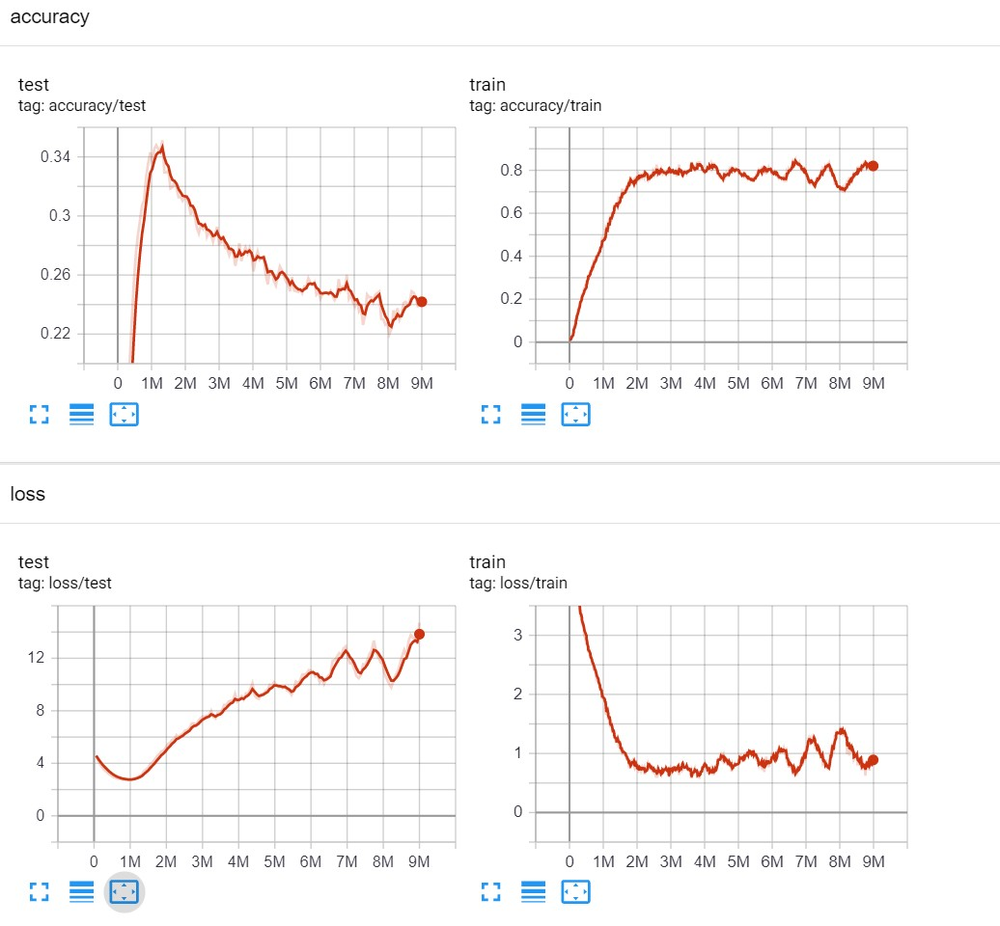

 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 9**

Possiamo dire che la rete converge? Perchè? Come mai la differenza tra accuracy di training e accuracy di test aumenta all'aumentare del numero di epoche?

**Risposta**: la rete è andata in overfitting, questo si nota perché la loss di training è bassa mentre quella di test sale.

Calcoliamo l'accuracy di test:

In [26]:
lenet_cifar100_test_predictions, cifar100_labels_test = test_classifier(lenet_cifar100,
                                                                        cifar100_test_loader)
print("Accuracy LeNetColor su CIFAR-100: %0.2f" % \
    accuracy_score(cifar100_labels_test,lenet_cifar100_test_predictions))

Accuracy LeNetColor su CIFAR-100: 0.28


L'accuracy è piuttosto bassa. Proviamo a migliorarla aumentando la capacità del modello. Definiamo un modello più "profondo" con 5 livelli di convoluzione e tre layer fully connected. Inseriremo il max pooling solo tra il primo e secondo livello, il secondo e il terzo, e il quinto e il sesto. Per evitare l'eccessiva riduzione di dimensioni delle mappe di features, specifichiamo un padding pari al ceil della dimensione del kernel fratto 2. Questo farà sì che le convoluzioni non riducano le dimensioni delle mappe di features. Utilizziamo kernel di dimensioni più grandi nei primi layer e più piccoli nei layer successivi. Il modello è vagamente ispirato al modello "AlexNet" proposto da Krizhevsky et al. nel 2013.

In [28]:
from torch import nn

class MiniAlexNet(nn.Module):
    def __init__(self, input_channels=3, out_classes=100):
        super(MiniAlexNet, self).__init__()

        self.feature_extractor = nn.Sequential(
            # Conv1:
            # - Input canali: input_channels
            # - Output canali (feature maps): 16
            # - Dimensione Kernel: 5x5
            # - Padding: 2
            # (Aggiungi subito dopo Max Pooling 2x2 e ReLU)
            nn.Conv2d(input_channels, 16, 5, padding=2),
            nn.MaxPool2d(2),
            nn.ReLU(),

            # Conv2:
            # - Input canali: 16
            # - Output canali: 32
            # - Dimensione Kernel: 5x5
            # - Padding: 2
            # (Aggiungi subito dopo Max Pooling 2x2 e ReLU)
            nn.Conv2d(16, 32, 5, padding=2),
            nn.MaxPool2d(2),
            nn.ReLU(),

            # Conv3:
            # - Input canali: 32
            # - Output canali: 64
            # - Dimensione Kernel: 3x3
            # - Padding: 1
            # (Aggiungi subito dopo ReLU - NESSUN Pooling)
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),

            # Conv4:
            # - Input canali: 64
            # - Output canali: 128
            # - Dimensione Kernel: 3x3
            # - Padding: 1
            # (Aggiungi subito dopo ReLU - NESSUN Pooling)
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),

            # Conv5:
            # - Input canali: 128
            # - Output canali: 256
            # - Dimensione Kernel: 3x3
            # - Padding: 1
            # (Aggiungi subito dopo Max Pooling 2x2 e ReLU)
            nn.Conv2d(128, 256, 3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            # FC6:
            # - Calcola la dimensione esatta dell'input tenendo conto
            #   dei canali in uscita dal feature extractor (256) e
            #   delle tre riduzioni spaziali (MaxPool2d) applicate all'immagine originale 32x32.
            # - Output unità: 2048
            # (Aggiungi subito dopo ReLU)
            nn.Linear(256 * 4 * 4, 2048),
            nn.ReLU(),

            # FC7:
            # - Input unità: 2048
            # - Output unità: 1024
            # (Aggiungi subito dopo ReLU)
            nn.Linear(2048, 1024),
            nn.ReLU(),

            # FC8:
            # - Input unità: 1024
            # - Output unità: out_classes
            nn.Linear(1024, out_classes)
        )

    def forward(self, x):
        # Applica il feature extractor, effettua il reshape del tensore
        # (flatten) e passa il risultato al classificatore
        x = self.feature_extractor(x)
        x = self.classifier(x.view(x.shape[0], -1))
        return x


In [29]:
# --- SANITY CHECK VISIVO: MiniAlexNet ---
import torch
try:
    modello_alexnet = MiniAlexNet()
    out_alexnet = modello_alexnet(torch.randn(4, 3, 32, 32))
    print(f"Shape ottenuta: {out_alexnet.shape} - Attesa: torch.Size([4, 100])")
except NotImplementedError:
    print("Implementa la classe MiniAlexNet!")
except Exception as e:
    print(f"Errore durante l'esecuzione del modello: {e}")

Shape ottenuta: torch.Size([4, 100]) - Attesa: torch.Size([4, 100])


Alleniamo il modello:

In [30]:
mini_alexnet_cifar100 = MiniAlexNet()
#Ai fini didattici alleniamo il modello solo per 15 epoche invece di 150
mini_alexnet_cifar100 = train_classifier(mini_alexnet_cifar100, cifar100_train_loader,
                                         cifar100_test_loader, \
                                  'minialexnet_cifar100', epochs=15)

In [31]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 3547), started 0:55:52 ago. (Use '!kill 3547' to kill it.)

<IPython.core.display.Javascript object>

Le curve di training/test dovrebbero essere simili alle seguenti:

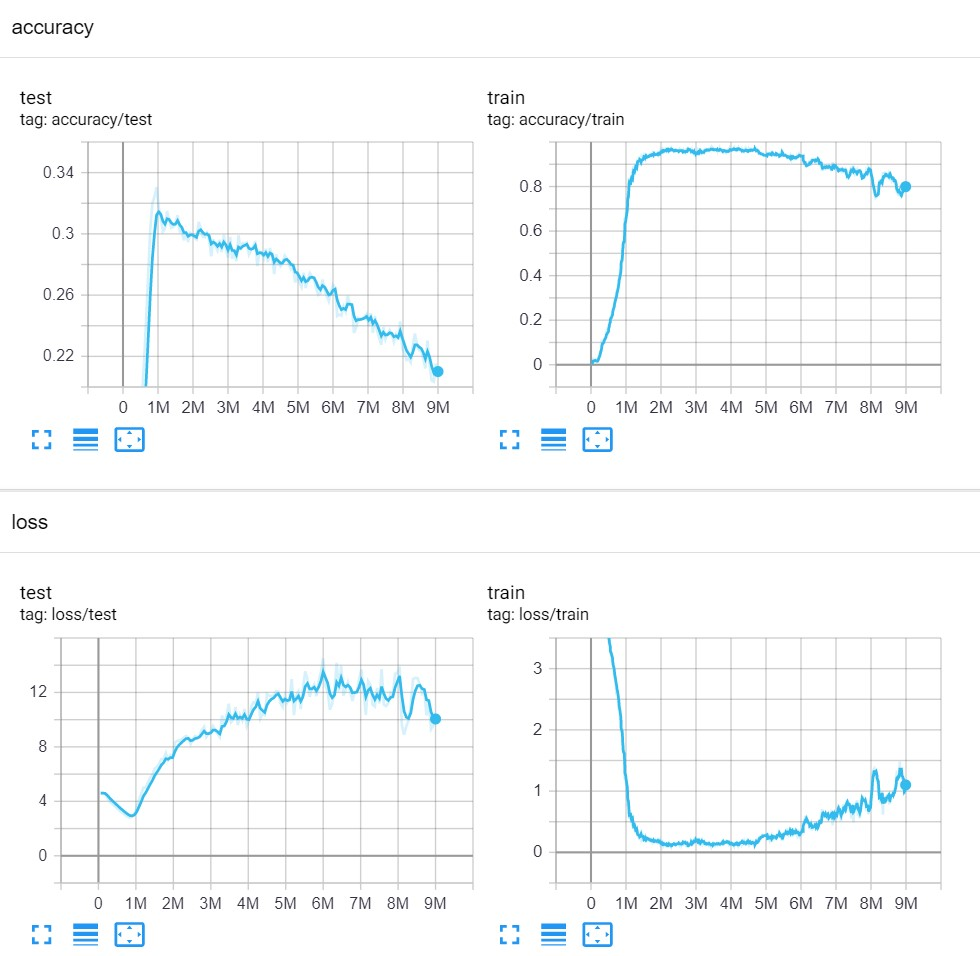

Calcoliamo l'accuracy di test e confrontiamola con quella del precedente modello:

In [32]:
minialexnet_cifar100_test_predictions, cifar100_labels_test = test_classifier(mini_alexnet_cifar100,
                                                                              cifar100_test_loader)
print("Accuracy LeNetColor su CIFAR-100: %0.2f" % \
    accuracy_score(cifar100_labels_test,lenet_cifar100_test_predictions))
print("Accuracy MiniAlexNet su CIFAR-100: %0.2f" % \
    accuracy_score(cifar100_labels_test,minialexnet_cifar100_test_predictions))

Accuracy LeNetColor su CIFAR-100: 0.28
Accuracy MiniAlexNet su CIFAR-100: 0.33


 <img src="https://cdn-icons-png.flaticon.com/512/5726/5726678.png" width="70" height="70" style="vertical-align:middle; margin-right:8px; float:left; margin-right:15px;"/> **Domanda 10**

Confrontare le curve di loss e accuracy di MiniAlexNet con quelle di LeNetColor. Quale dei due modelli soffre di più di overfitting. Perché?

**Risposta**: MiniAlexNet va leggermente meglio, ma comunque sembra andare in overfitting. Una cosa da notare è che, in 15 epoche non si riesce a vedere bene la curva di Loss cominciare a salire (chiaro sintomo di overfitting) come si vede in quella da 150.

# References

 * Documentazione di PyTorch. http://pytorch.org/docs/stable/index.html